In [2]:
#Mount Google Drive

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install -q ultralytics

In [4]:
#Set your dataset path

DATA_YAML = r"/content/drive/MyDrive/DATASETS/Pillar Detection.v1-pillar-detection-v1.yolov8/data.yaml"

In [5]:
#Verify the dataset

import os
import yaml

assert os.path.isfile(DATA_YAML), f"data.yaml not found: {DATA_YAML}"

with open(DATA_YAML, "r") as f:
    data = yaml.safe_load(f)

print("Dataset:", DATA_YAML)
print("Classes:", data["names"])
print("Number of classes:", data["nc"])
print("Training path:", data.get("train"))
print("Validation path:", data.get("val"))
print("Test path:", data.get("test"))

Dataset: /content/drive/MyDrive/DATASETS/Pillar Detection.v1-pillar-detection-v1.yolov8/data.yaml
Classes: ['Pillar']
Number of classes: 1
Training path: ../train/images
Validation path: ../valid/images
Test path: ../test/images


In [6]:
#Check GPU availability

import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable GPU: Runtime > Change runtime type > T4 GPU")

GPU available: True
GPU: Tesla T4


In [7]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=8,
    patience=10,
    device=0,
    workers=2,
    seed=42,
    pretrained=True,
    project="/content/runs/pillar",
    name="yolov8n_pillar_v1",
    exist_ok=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/DATASETS/Pillar Detection.v1-pillar-detection-v1.yolov8/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, 

In [8]:
best_model = YOLO(
    "/content/runs/pillar/yolov8n_pillar_v1/weights/best.pt"
)

metrics = best_model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    device=0
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.2 ms, read: 0.0±0.0 MB/s, size: 25.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/DATASETS/Pillar Detection.v1-pillar-detection-v1.yolov8/test/labels... 3 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3/3 1.6it/s 1.9s
val: New cache created: /content/drive/MyDrive/DATASETS/Pillar Detection.v1-pillar-detection-v1.yolov8/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 1, len(boxes) = 3. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images 

In [9]:
import os
import shutil

src = "/content/runs/pillar/yolov8n_pillar_v1/weights/best.pt"
dst = "/content/drive/MyDrive/Pillar_Project/best_pillar.pt"

os.makedirs(os.path.dirname(dst), exist_ok=True)
shutil.copy2(src, dst)

print("Model saved:", dst)

Model saved: /content/drive/MyDrive/Pillar_Project/best_pillar.pt


In [11]:
#Load your trained model

from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/Pillar_Project/best_pillar.pt")

print("Pillar detection model loaded successfully!")

Pillar detection model loaded successfully!


In [16]:
#Test one of your own images

IMAGE_PATH = "/content/drive/MyDrive/DATASETS/Pillar Detection.v1-pillar-detection-v1.yolov8/test/images/pillar-24-_jpeg.rf.2bd08f58de50f90d6565e4831d514365.jpg"

results = model.predict(
    source=IMAGE_PATH,
    imgsz=640,
    conf=0.25,
    save=True
)

print("Detection completed!")


image 1/1 /content/drive/MyDrive/DATASETS/Pillar Detection.v1-pillar-detection-v1.yolov8/test/images/pillar-24-_jpeg.rf.2bd08f58de50f90d6565e4831d514365.jpg: 640x480 1 Pillar, 11.8ms
Speed: 0.9ms preprocess, 11.8ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict
Detection completed!


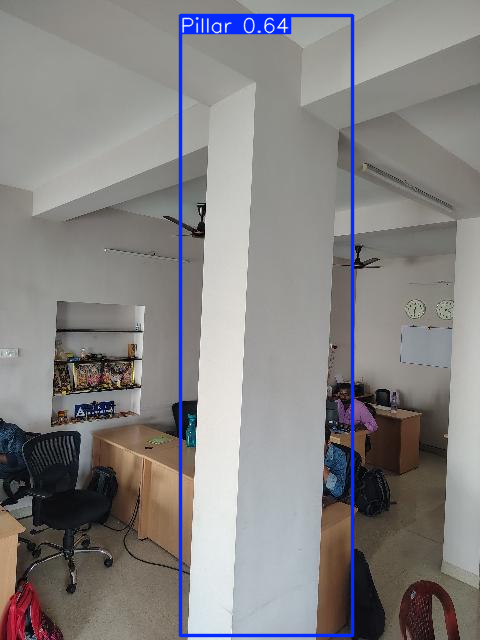

In [17]:
#Display the detected pillar

from IPython.display import display
from PIL import Image

result_image = results[0].plot()
display(Image.fromarray(result_image[:, :, ::-1]))